# 03 · Cont–Kokholm: checking the implementation

Notebook 02 shows what the model does. This one checks that the code does it correctly,
by comparing quantities that are computed in two independent ways:

1. **Martingales.** Forward variance swap rates and the discounted index must have constant
   expectation under the pricing measure.
2. **Fourier vs Fourier.** The Kar–Madan and Cont–Tankov FFT pricers must agree.
3. **Fourier vs Monte Carlo.** VIX option prices from the characteristic function must match
   prices from the simulated variance paths.
4. **Jump terms.** Simulated damped jump sums must have the moments the jump law implies.
5. **Convergence.** Monte Carlo index prices must converge at the $1/\sqrt{N}$ rate.

Maths: [docs/cont_kokholm.md](../docs/cont_kokholm.md).

In [1]:
import warnings

import _style as st
import matplotlib.pyplot as plt
import numpy as np

from finpricing import VixModel
from finpricing.data.fixtures import (
    KOU_B_I,
    KOU_PARAMS,
    MERTON_B_I,
    MERTON_PARAMS,
    TENOR_DATES,
    VI_0,
)
from finpricing.models.vix.model import get_sigmas, get_UTm
from finpricing.models.vix.pricing import price_vix_options

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(7)

NUM_PATHS = 400_000
LABELS = [f"{round(T * 12)}m" for T in TENOR_DATES[1:]]
COLORS = {"Merton": st.OXIDE, "Kou": st.INDIGO}
PARAMS = {"Merton": (MERTON_PARAMS, MERTON_B_I), "Kou": (KOU_PARAMS, KOU_B_I)}

models = {name: VixModel(model_type=name) for name in PARAMS}
for model in models.values():
    model.store_tenor_data(NUM_PATHS)

## 1 · Martingale checks

For each tenor, $\mathbb{E}[V^i_{T_i}] / V^i_0$ and $\mathbb{E}[S_{T_k}] / S_0$ should equal 1.
Bars are 99% confidence intervals from the simulation.

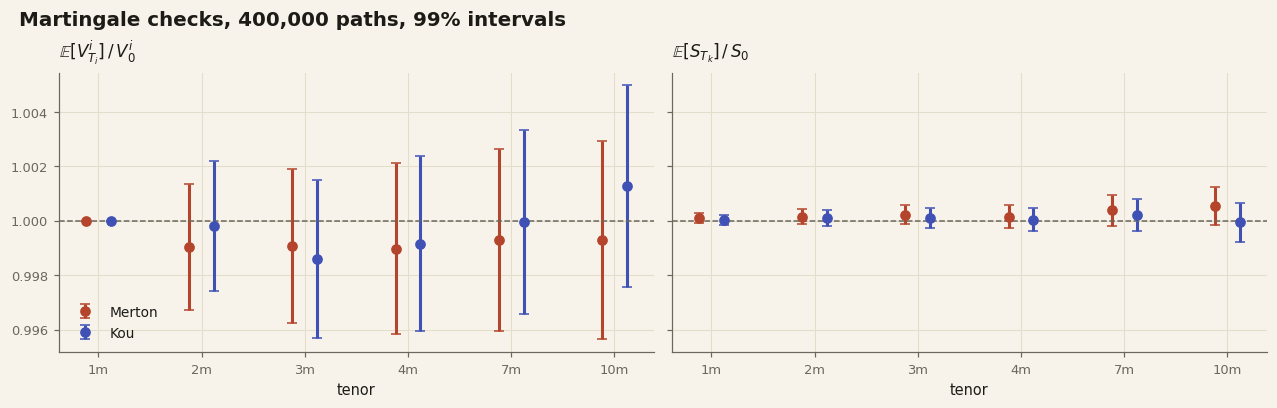

PASS  Merton: every forward variance and index ratio has mean 1 (max |z| = 1.94)
PASS  Kou: every forward variance and index ratio has mean 1 (max |z| = 1.25)


In [2]:
n_tenors = len(TENOR_DATES) - 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
offsets = {"Merton": -0.12, "Kou": 0.12}
worst_z = {}
for name, model in models.items():
    params, b_i = PARAMS[name]
    _, diff_Z, jumps_S, _, VTi = model._stored_data
    ratio = VTi / VI_0
    v_mean, v_se = ratio.mean(0), ratio.std(0) / np.sqrt(NUM_PATHS)

    sigmas_sq = get_sigmas(VI_0, VTi, model.constraint_cf, b_i)
    U = np.column_stack([
        get_UTm(VI_0[:k], VTi[:, :k], diff_Z[:, :k], jumps_S[:, :k], sigmas_sq[:, :k],
                b_i[:k], TENOR_DATES[:k + 1], params)
        for k in range(1, n_tenors + 1)
    ])
    u_mean, u_se = U.mean(0), U.std(0) / np.sqrt(NUM_PATHS)

    x = np.arange(n_tenors) + offsets[name]
    # V^1 is fixed at time 0, so its first entry is exactly 1 with no error bar.
    ax1.errorbar(x, v_mean, yerr=2.58 * v_se, fmt="o", color=COLORS[name], capsize=3, label=name)
    ax2.errorbar(x, u_mean, yerr=2.58 * u_se, fmt="o", color=COLORS[name], capsize=3, label=name)
    with np.errstate(invalid="ignore", divide="ignore"):
        z = np.concatenate([((v_mean - 1) / v_se)[1:], (u_mean - 1) / u_se])
    worst_z[name] = np.max(np.abs(z))

for ax, title in [(ax1, r"$\mathbb{E}[V^i_{T_i}] \,/\, V^i_0$"), (ax2, r"$\mathbb{E}[S_{T_k}] \,/\, S_0$")]:
    ax.axhline(1, color=st.MUTED, lw=1, ls="--")
    ax.set_xticks(range(n_tenors), LABELS)
    ax.set(title=title, xlabel="tenor")
ax1.legend(loc="lower left")
fig.suptitle(f"Martingale checks, {NUM_PATHS:,} paths, 99% intervals", x=0.01, ha="left")
plt.show()

for name, z in worst_z.items():
    st.check(z < 4, f"{name}: every forward variance and index ratio has mean 1 (max |z| = {z:.2f})")

## 2 · Two FFT pricers agree

Kar–Madan transforms the damped call price; Cont–Tankov transforms the difference from a
Black–Scholes price with the same forward. Different transforms, different grids: the
prices should agree to well below a basis point of the underlying.

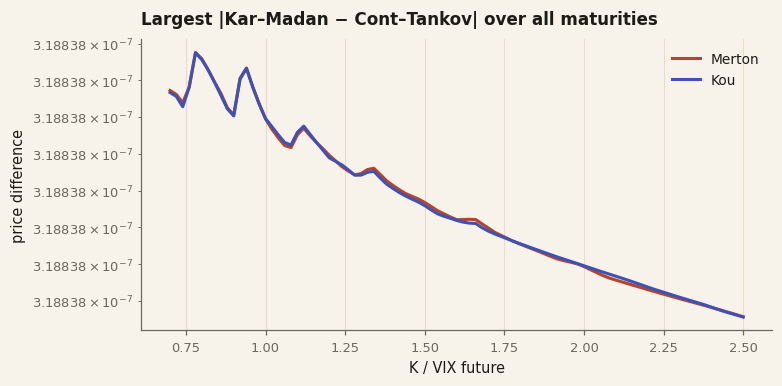

PASS  Merton: FFT pricers agree to 3.2e-07 (VIX future = 1)
PASS  Kou: FFT pricers agree to 3.2e-07 (VIX future = 1)


In [3]:
ks = np.linspace(0.7, 2.5, 91)
fig, ax = plt.subplots(figsize=(7, 3.4))
max_diff = {}
for name, (params, _) in PARAMS.items():
    diffs = []
    for T in TENOR_DATES[1:]:
        km = np.array([price_vix_options(1.0, k, T, 0.0, params, "Kar&Madan") for k in ks])
        ct = np.array([price_vix_options(1.0, k, T, 0.0, params, "Cont&Tankov") for k in ks])
        diffs.append(np.abs(km - ct))
    diffs = np.array(diffs)
    max_diff[name] = diffs.max()
    ax.semilogy(ks, diffs.max(0) + 1e-16, color=COLORS[name], label=name)
ax.set(title="Largest |Kar–Madan − Cont–Tankov| over all maturities", xlabel="K / VIX future",
       ylabel="price difference")
ax.legend()
plt.show()

for name, d in max_diff.items():
    st.check(d < 1e-5, f"{name}: FFT pricers agree to {d:.1e} (VIX future = 1)")

## 3 · Fourier against Monte Carlo

The VIX at $T_i$ is $\sqrt{V^i_{T_i}}$ up to a constant, so each simulated variance path also
gives a VIX option payoff. Normalising the simulated VIX to have mean 1 (the futures price)
and averaging the payoff must reproduce the Fourier price. The plot shows the difference in
units of the Monte Carlo standard error; agreement means staying inside the ±3 band.

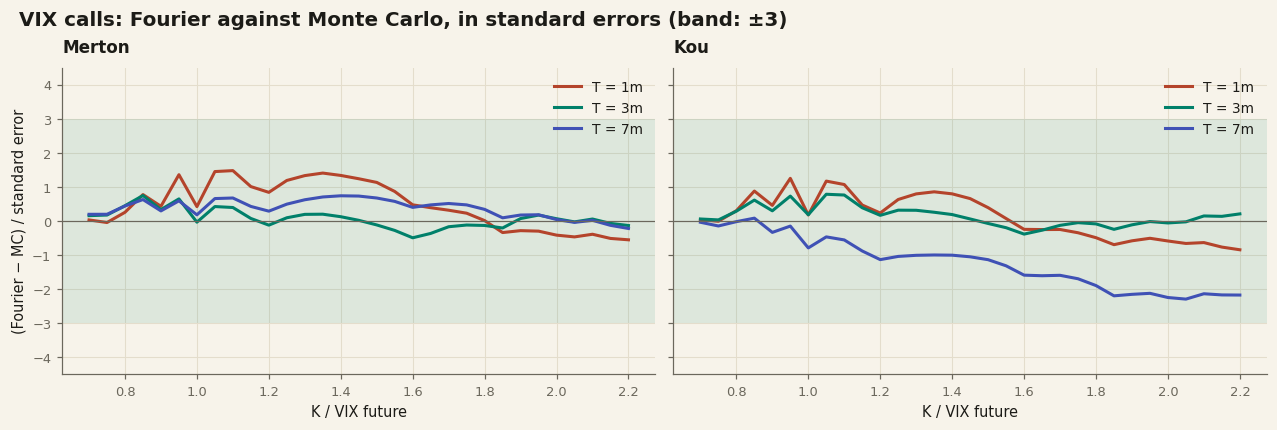

PASS  Merton: Fourier and Monte Carlo VIX prices agree (max |z| = 1.48)
PASS  Kou: Fourier and Monte Carlo VIX prices agree (max |z| = 2.30)


In [4]:
check_ks = np.linspace(0.7, 2.2, 31)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
max_abs_z = {}
for ax, (name, model) in zip(axes, models.items(), strict=True):
    params, _ = PARAMS[name]
    VTi = model._stored_data[4]
    zs = []
    for i, color in [(1, st.OXIDE), (3, st.VERDIGRIS), (5, st.INDIGO)]:
        T = TENOR_DATES[i]
        vix = np.sqrt(VTi[:, i] / VI_0[i])
        vix /= vix.mean()
        payoff = np.maximum(vix[:, None] - check_ks, 0)
        mc, se = payoff.mean(0), payoff.std(0) / np.sqrt(NUM_PATHS)
        fourier = np.array([price_vix_options(1.0, k, T, 0.0, params) for k in check_ks])
        zs.append((fourier - mc) / se)
        ax.plot(check_ks, zs[-1], color=color, label=f"T = {LABELS[i - 1]}")
    max_abs_z[name] = np.max(np.abs(zs))
    ax.axhspan(-3, 3, color=st.VERDIGRIS, alpha=0.10, lw=0)
    ax.axhline(0, color=st.MUTED, lw=0.8)
    ax.set_ylim(-4.5, 4.5)
    ax.set(title=f"{name}", xlabel="K / VIX future")
    ax.legend(loc="upper right")
axes[0].set_ylabel("(Fourier − MC) / standard error")
fig.suptitle("VIX calls: Fourier against Monte Carlo, in standard errors (band: ±3)", x=0.01, ha="left")
plt.show()

for name, z in max_abs_z.items():
    st.check(z < 4, f"{name}: Fourier and Monte Carlo VIX prices agree (max |z| = {z:.2f})")

## 4 · The simulated jump terms have the right moments

The jump part of $\ln V^i_{T_i}$ is $J_i = \sum_{\tau_j < T_i} e^{-k_2 (T_i - \tau_j)} Y_j$, a
compound Poisson sum with intensity $\lambda$. Its mean and variance follow from the jump law:

$$\mathbb{E}[J_i] = \lambda\, \mathbb{E}[Y]\, \frac{1 - e^{-k_2 T_i}}{k_2}, \qquad
  \mathrm{Var}[J_i] = \lambda\, \mathbb{E}[Y^2]\, \frac{1 - e^{-2 k_2 T_i}}{2 k_2}.$$

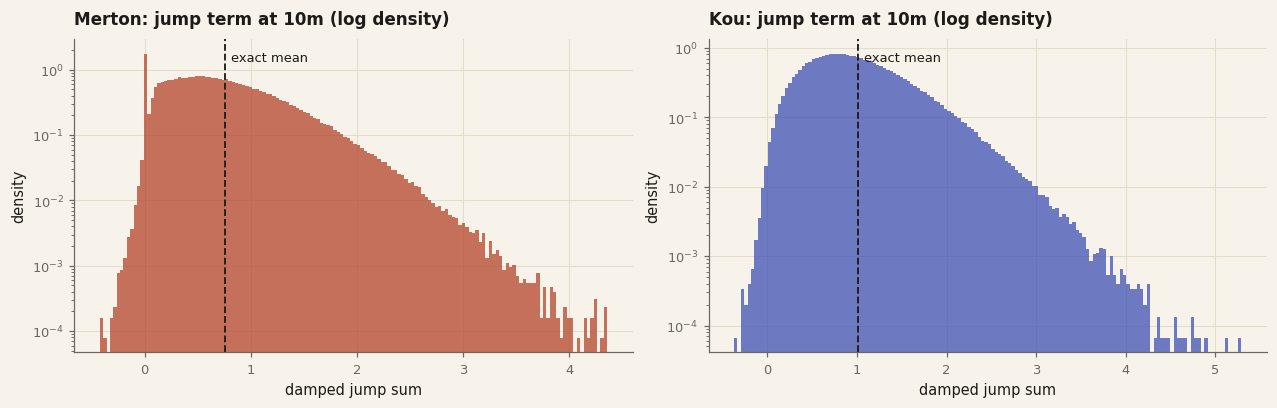

PASS  Merton: jump-term mean (max |z| = 1.84) and variance (max error 0.48%) match
PASS  Kou: jump-term mean (max |z| = 0.89) and variance (max error 0.51%) match


In [5]:
def jump_moments(params):
    if params.model_type == "Merton":
        return params.m, params.m**2 + params.delta**2
    p, ap, am = params.p, params.alpha_plus, params.alpha_minus
    return p / ap - (1 - p) / am, 2 * p / ap**2 + 2 * (1 - p) / am**2


fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
moment_errors = {}
for ax, (name, model) in zip(axes, models.items(), strict=True):
    params, _ = PARAMS[name]
    jumps_V = model._stored_data[3]
    ey, ey2 = jump_moments(params)
    T = TENOR_DATES[1:]
    mean_exact = params.lmbd * ey * (1 - np.exp(-params.k2 * T)) / params.k2
    var_exact = params.lmbd * ey2 * (1 - np.exp(-2 * params.k2 * T)) / (2 * params.k2)
    mean_z = (jumps_V.mean(0) - mean_exact) / np.sqrt(var_exact / NUM_PATHS)
    var_rel = jumps_V.var(0) / var_exact - 1
    moment_errors[name] = (np.max(np.abs(mean_z)), np.max(np.abs(var_rel)))

    last = jumps_V[:, -1]
    ax.hist(last, bins=150, density=True, color=COLORS[name], alpha=0.75, log=True)
    ax.axvline(mean_exact[-1], color=st.INK, lw=1.2, ls="--")
    ax.annotate("exact mean", (mean_exact[-1], ax.get_ylim()[1]), xytext=(4, -14), textcoords="offset points",
                fontsize=8.5, color=st.INK)
    ax.set(title=f"{name}: jump term at {LABELS[-1]} (log density)", xlabel="damped jump sum", ylabel="density")
plt.show()

for name, (z, rel) in moment_errors.items():
    st.check(z < 4 and rel < 0.02, f"{name}: jump-term mean (max |z| = {z:.2f}) and variance (max error {rel:.2%}) match")

## 5 · Monte Carlo convergence

Index options are priced by averaging over simulated variance paths. The error of the
average should fall like $1/\sqrt{N}$. Here the 4-month at-the-money index call is priced
30 times at each sample size and compared with a 1,000,000-path reference.

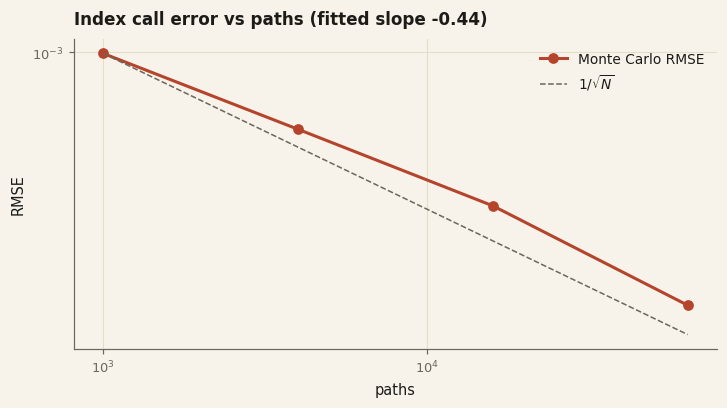

PASS  Monte Carlo error falls like 1/√N (slope -0.44)


In [6]:
model = VixModel(model_type="Merton")
model.store_tenor_data(1_000_000)
reference = model.index_option_pricer(S0=1.0, strikes=np.array([1.0]), tenor_index=4)[0]

sizes = np.array([1_000, 4_000, 16_000, 64_000])
rmse = []
for n in sizes:
    estimates = []
    for _ in range(30):
        model.store_tenor_data(n)
        estimates.append(model.index_option_pricer(S0=1.0, strikes=np.array([1.0]), tenor_index=4)[0])
    rmse.append(np.sqrt(np.mean((np.array(estimates) - reference) ** 2)))
rmse = np.array(rmse)
slope = np.polyfit(np.log(sizes), np.log(rmse), 1)[0]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.loglog(sizes, rmse, "o-", color=st.OXIDE, label="Monte Carlo RMSE")
ax.loglog(sizes, rmse[0] * np.sqrt(sizes[0] / sizes), color=st.MUTED, ls="--", lw=1, label=r"$1/\sqrt{N}$")
ax.set(title=f"Index call error vs paths (fitted slope {slope:.2f})", xlabel="paths", ylabel="RMSE")
ax.minorticks_off()
ax.legend()
plt.show()

st.check(-0.65 < slope < -0.35, f"Monte Carlo error falls like 1/√N (slope {slope:.2f})")

In [7]:
st.summary()

9/9 checks passed
  PASS  Merton: every forward variance and index ratio has mean 1 (max |z| = 1.94)
  PASS  Kou: every forward variance and index ratio has mean 1 (max |z| = 1.25)
  PASS  Merton: FFT pricers agree to 3.2e-07 (VIX future = 1)
  PASS  Kou: FFT pricers agree to 3.2e-07 (VIX future = 1)
  PASS  Merton: Fourier and Monte Carlo VIX prices agree (max |z| = 1.48)
  PASS  Kou: Fourier and Monte Carlo VIX prices agree (max |z| = 2.30)
  PASS  Merton: jump-term mean (max |z| = 1.84) and variance (max error 0.48%) match
  PASS  Kou: jump-term mean (max |z| = 0.89) and variance (max error 0.51%) match
  PASS  Monte Carlo error falls like 1/√N (slope -0.44)
